In [2]:
# from tqdm import tqdm
# from datetime import datetime, timezone
import pandas as pd
import os, warnings
# from pandas.errors import ParserWarning
# import matplotlib.pyplot as plt
# import numpy as np
# import plotly.express as px
# import plotly.graph_objects as go
# warnings.simplefilter('ignore', ParserWarning)
# warnings.simplefilter('ignore', UserWarning)
# import plotly.io as pio
# import seaborn as sns
# from sklearn.preprocessing import StandardScaler
# import random
# from scipy import stats
from statsmodels.stats.descriptivestats import sign_test
from anchor import data_dir,experiment_dir

In [3]:
# ANCHOR = Path.cwd()
data_root  = data_dir()#os.path.join(ANCHOR,"Data")
experiment_root = experiment_dir()
experiment_path = os.path.join(experiment_root,"leave_1_without_finetuning_fixed")
# activity_root = os.path.join(data_root,'Activity Diaries')
# output_root = os.path.join(ANCHOR, "Output")

experiment_result_folders = [name for name in os.listdir(experiment_path) if (os.path.isdir(os.path.join(experiment_path,name))) & (name[-1] != "_")]
# baseline_results_folders = [name for name in experiment_result_folders if "baseline" in name]
non_basline_results_folders = [name for name in experiment_result_folders if "baseline" not in name]
# print(baseline_results_folders)
print(non_basline_results_folders)

['iter0_cluster_predictions', 'iter10_cluster_predictions', 'iter11_cluster_predictions', 'iter12_cluster_predictions', 'iter13_cluster_predictions', 'iter14_cluster_predictions', 'iter15_cluster_predictions', 'iter16_cluster_predictions', 'iter17_cluster_predictions', 'iter18_cluster_predictions', 'iter19_cluster_predictions', 'iter1_cluster_predictions', 'iter2_cluster_predictions', 'iter3_cluster_predictions', 'iter4_cluster_predictions', 'iter5_cluster_predictions', 'iter6_cluster_predictions', 'iter7_cluster_predictions', 'iter8_cluster_predictions', 'iter9_cluster_predictions']


In [4]:

# baseline_result_list = []
# for baseline_results_folder in baseline_results_folders:
#     for file_name in os.listdir(os.path.join(experiment_path,baseline_results_folder)):
#         df = pd.read_csv(os.path.join(experiment_path,baseline_results_folder,file_name))
#         baseline_result_list.append(df)
# baseline_result = pd.concat(baseline_result_list)


cohort_result_list = []
for non_basline_results_folder in non_basline_results_folders:
    for file_name in os.listdir(os.path.join(experiment_path,non_basline_results_folder)):
        df = pd.read_csv(os.path.join(experiment_path,non_basline_results_folder,file_name))
        cohort_result_list.append(df)
cohort_result = pd.concat(cohort_result_list)

### looking at data & how the difference between prediction and baseline differentiate. (Most statistical assumptions are on the distribution of this difference)

In [5]:
# baseline_result["true_pred_diff"] = baseline_result.true - baseline_result.pred
cohort_result["cohort_diff"] = cohort_result.true - cohort_result.pred
cohort_result["baseline_diff"] = cohort_result.true - cohort_result.baseline_pred
#cohort_result["difference"] = cohort_result["cohort_diff"] - cohort_result["baseline_diff"]
cohort_result["abs_cohort_diff"] = abs(cohort_result["cohort_diff"] )
cohort_result["abs_baseline_diff"] = abs(cohort_result["baseline_diff"] )
cohort_result["abs_difference"] = cohort_result["abs_cohort_diff"] - cohort_result["abs_baseline_diff"]
# negative means that baseline is worse, positive means cohort is worse
# diff = baseline_result["true_pred_diff"] - cohort_result["true_pred_diff"]

In [6]:
print(cohort_result.cohort_diff.sum())
print(cohort_result.baseline_diff.sum())
print(cohort_result.abs_difference.sum())

-52
61
27


In [7]:
cohort_result.loc[cohort_result.abs_difference != 0]

,user,timestamp,true,pred,baseline_pred,cohort_diff,baseline_diff,abs_cohort_diff,abs_baseline_diff,abs_difference
21,id022,2025-05-01 06:13:34+00:00,11,11,10,0,1,0,1,-1
26,id022,2025-05-04 16:49:45+00:00,11,11,10,0,1,0,1,-1
39,id022,2025-05-07 10:15:43+00:00,10,11,10,-1,0,1,0,1
64,id022,2025-05-12 07:44:48+00:00,11,11,10,0,1,0,1,-1
83,id022,2025-05-15 17:57:19+00:00,11,11,10,0,1,0,1,-1
...,...,...,...,...,...,...,...,...,...,...
45,id031,2025-05-11 19:59:38+00:00,11,11,10,0,1,0,1,-1
52,id031,2025-05-15 07:30:25+00:00,10,11,10,-1,0,1,0,1
56,id031,2025-05-16 13:30:22+00:00,11,11,10,0,1,0,1,-1
63,id031,2025-05-19 20:14:32+00:00,10,11,10,-1,0,1,0,1


# Sign test: Should always be applicable

In [11]:
diff_data = cohort_result["abs_difference"]

m, p_value = sign_test(diff_data,0)

print("Test Statistic (M):", m)
print("P-value:", p_value)

# Interpretation
alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis: The median difference is not zero.")
else:
    print("Fail to reject the null hypothesis: No significant difference.")

Test Statistic (M): 13.5
P-value: 0.015864496824406386
Reject the null hypothesis: The median difference is not zero.


# Check for Assumptions (Normality, Symmetry)

mean=0.013 stdv=0.240


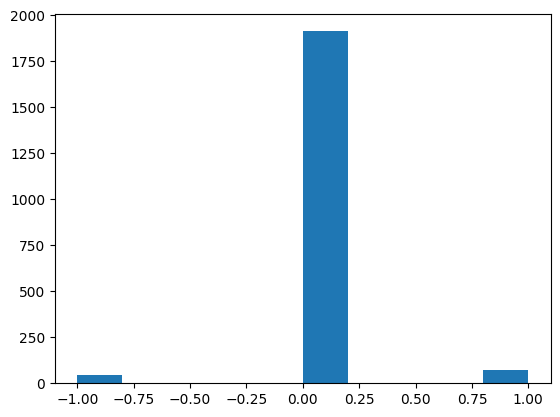

In [ ]:
import numpy as np
from matplotlib import pyplot


print('mean=%.3f stdv=%.3f' % (np.mean(diff_data), np.std(diff_data)))
pyplot.hist(diff_data)
pyplot.show()

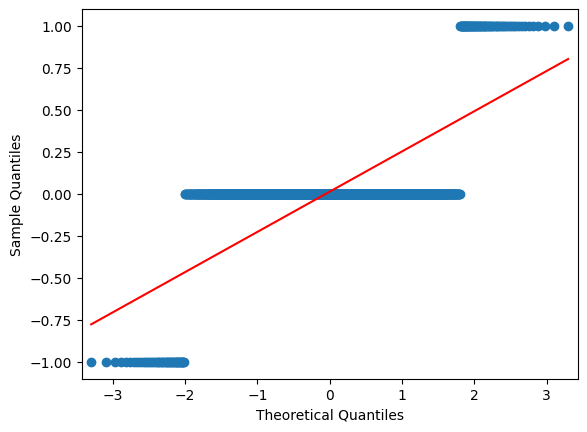

In [14]:
from statsmodels.graphics.gofplots import qqplot
qqplot(diff_data, line='s')
pyplot.show()

In [ ]:
from scipy.stats import shapiro
from scipy.stats import normaltest
from scipy.stats import anderson

# Shapiro normality test
stat, p = shapiro(diff_data)
print('Statistics=%.3f, p=%.3f' % (stat, p))
# interpret
alpha = 0.05
if p > alpha:
	print('Sample looks Gaussian (fail to reject H0)')
else:
	print('Sample does not look Gaussian (reject H0)')
	
# K^2 normality test
stat, p = normaltest(diff_data)
print('Statistics=%.3f, p=%.3f' % (stat, p))
# interpret
alpha = 0.05
if p > alpha:
	print('Sample looks Gaussian (fail to reject H0)')
else:
	print('Sample does not look Gaussian (reject H0)')
	
# anderson normality test
result = anderson(diff_data)
print('Statistic: %.3f' % result.statistic)
p = 0
for i in range(len(result.critical_values)):
	sl, cv = result.significance_level[i], result.critical_values[i]
	if result.statistic < result.critical_values[i]:
		print('%.3f: %.3f, data looks normal (fail to reject H0)' % (sl, cv))
	else:
		print('%.3f: %.3f, data does not look normal (reject H0)' % (sl, cv))

# Looks pretty bad :P Not sure if we can use the assumption of normality

Statistics=0.298, p=0.000
Sample does not look Gaussian (reject H0)
Statistics=610.578, p=0.000
Sample does not look Gaussian (reject H0)
Statistic: 662.893
15.000: 0.575, data does not look normal (reject H0)
10.000: 0.655, data does not look normal (reject H0)
5.000: 0.785, data does not look normal (reject H0)
2.500: 0.916, data does not look normal (reject H0)
1.000: 1.090, data does not look normal (reject H0)


# check for skewness/assymetry


In [ ]:
skewness = 3*(np.mean(diff_data)-np.median(diff_data))/np.std(diff_data)
print(skewness)
#not too bad => should be able to use Wilcoxon signed-rank test

0.16641954173271403


# Wilcoxon signed-rank test

In [24]:
from scipy.stats import wilcoxon


w, p_value = wilcoxon(x = diff_data,alternative='two-sided')


print("Test Statistic (W):", w)
print("P-value:", p_value)

# Interpretation
alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis: The median difference is not zero.")
else:
    print("Fail to reject the null hypothesis: No significant difference.")
# ids = ["id075", "id012", "id007", "id076", "id078", "id008", "id045", "id017", "id032", "id067", "id039", "id080", "id049", "id038", "id027", "id060", "id030", "id037", "id047", "id042", "id024", "id021", "id022", "id077", "id052", "id013", "id002", "id043", "id073", "id009", "id064", "id069", "id059", "id023", "id085", "id044", "id031", "id033", "id071", "id020", "id055", "id011", "id003", "id063", "id053", "id006", "id051", "id028", "id083", "id061", "id081", "id062", "id070", "id036"]
# ids.sort()
# ids

Test Statistic (W): 2655.0
P-value: 0.012554918596966533
Reject the null hypothesis: The median difference is not zero.


In [28]:
w, p_value = wilcoxon(x = diff_data,alternative='greater')


print("Test Statistic (W):", w)
print("P-value greater:", p_value)

alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis: the distribution underlying d is stochastically greater than a distribution symmetric about zero.")
else:
    print("Fail to reject the null hypothesis: the distribution underlying d is stochastically greater than a distribution symmetric about zero.")

w, p_value = wilcoxon(x = diff_data,alternative='less')


print("Test Statistic (W):", w)
print("P-value lesser", p_value)

if p_value < alpha:
    print("Reject the null hypothesis: he distribution underlying d is stochastically less than a distribution symmetric about zero.")
else:
    print("Fail to reject the null hypothesis: he distribution underlying d is stochastically less than a distribution symmetric about zero.")



Test Statistic (W): 4248.0
P-value greater: 0.006277459298483267
Reject the null hypothesis: the distribution underlying d is stochastically greater than a distribution symmetric about zero.
Test Statistic (W): 4248.0
P-value lesser 0.9937225407015168
Fail to reject the null hypothesis: he distribution underlying d is stochastically less than a distribution symmetric about zero.


In [29]:
from sklearn.metrics import f1_score